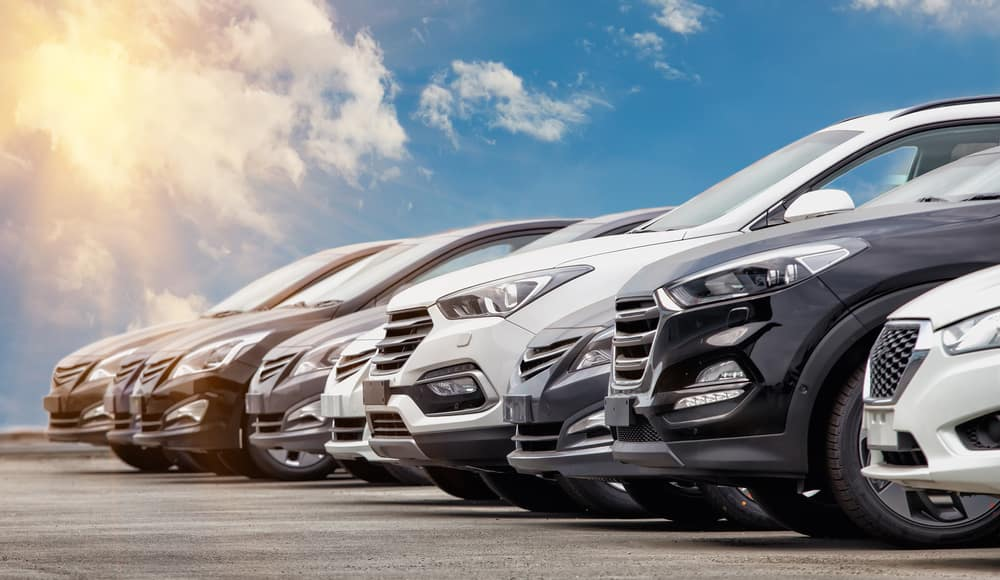


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        Description
   </p>
</div>



<div style="background-color: navy; padding: 20px; border-radius: 15px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        Used Car Prices in UK Dataset is a comprehensive collection of automotive information extracted from the popular automotive marketplace website, autotrader.co.uk. This dataset comprises 3,685 data points, each representing a unique vehicle listing, and includes thirteen distinct features providing valuable insights into the world of automobiles
   </p>
</div>


Columns :

* Price: The price of the car in a specific currency.
* Mileage(miles): The number of miles traveled by the car.
* Registration(year): The year when the car was registered.
* Previous Owners: The number of previous owners of the car.
* Fuel Type: The type of fuel used by the car.
* Body Type: The body type of the car (e.g., sedan, hatchback, SUV, etc.).
* Engine: The engine capacity of the car (typically in cc or liters).
* Gearbox: The type of transmission of the car (e.g., manual or automatic).
* Seats: The number of seats available in the car.
* Doors: The number of doors on the car.
* Emission Class: The emission class of the car based on exhaust emissions level.
* Service History: The service or maintenance history of the car.


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        1. Import Libraries
   </p>
</div>


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

from scipy import stats
from scipy.stats import f_oneway
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.preprocessing import RobustScaler
from sklearn.model_selection import train_test_split
from keras.models import Sequential
from keras.layers import Dense, Dropout
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


import warnings
warnings.filterwarnings('ignore') 



<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        2. Import Data
   </p>
</div>


In [2]:
df=pd.read_csv("/kaggle/input/used-cars-prices-in-uk/used_cars_UK.csv")

df.drop(['Unnamed: 0', 'Service history'], axis=1, inplace=True)

In [3]:
df.head()

,title,Price,Mileage(miles),Registration_Year,Previous Owners,Fuel type,Body type,Engine,Gearbox,Doors,Seats,Emission Class
0,SKODA Fabia,6900,70189,2016,3.0,Diesel,Hatchback,1.4L,Manual,5.0,5.0,Euro 6
1,Vauxhall Corsa,1495,88585,2008,4.0,Petrol,Hatchback,1.2L,Manual,3.0,5.0,Euro 4
2,Hyundai i30,949,137000,2011,NaN,Petrol,Hatchback,1.4L,Manual,5.0,5.0,Euro 5
3,MINI Hatch,2395,96731,2010,5.0,Petrol,Hatchback,1.4L,Manual,3.0,4.0,Euro 4
4,Vauxhall Corsa,1000,85000,2013,NaN,Diesel,Hatchback,1.3L,Manual,5.0,5.0,Euro 5


<Axes: >

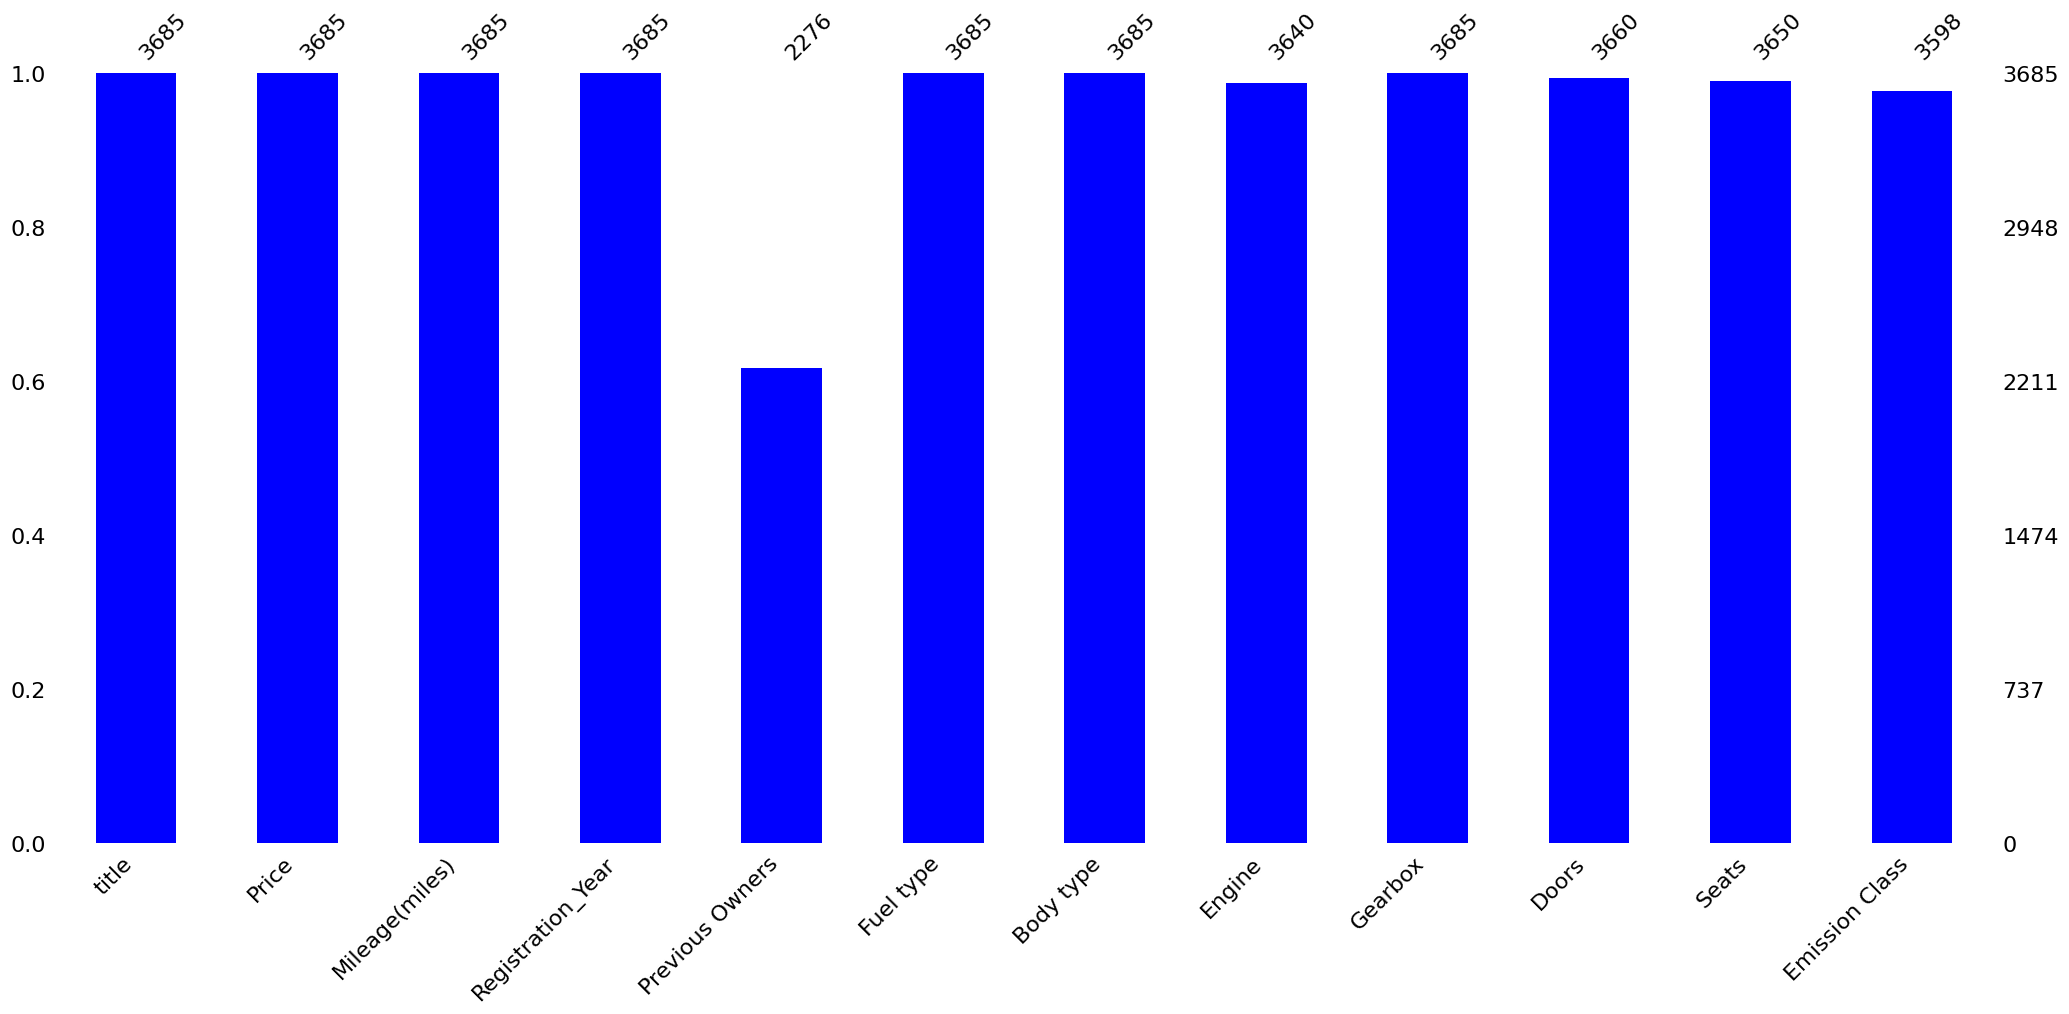

In [4]:
msno.bar(df, color = 'b')

In [5]:
def null_count():
    return pd.DataFrame({'features': df.columns,
                'dtypes': df.dtypes.values,
                'NaN count': df.isnull().sum().values,
                'NaN percentage': df.isnull().sum().values/df.shape[0]}).style.background_gradient(cmap='Set2',low=0.1,high=0.01)
null_count()

,features,dtypes,NaN count,NaN percentage
0,title,object,0,0.000000
1,Price,int64,0,0.000000
2,Mileage(miles),int64,0,0.000000
3,Registration_Year,int64,0,0.000000
4,Previous Owners,float64,1409,0.382361
5,Fuel type,object,0,0.000000
6,Body type,object,0,0.000000
7,Engine,object,45,0.012212
8,Gearbox,object,0,0.000000
9,Doors,float64,25,0.006784


In [6]:
print(f"Summary Of The Dataset with numerical columns :")
df.describe().style.set_properties(**{"background-color": "#121d6b","color":"#e9c46a","border": "1.5px solid black"})

Summary Of The Dataset with numerical columns :


,Price,Mileage(miles),Registration_Year,Previous Owners,Doors,Seats
count,3685.000000,3685.000000,3685.000000,2276.000000,3660.000000,3650.000000
mean,5787.145726,81328.164722,2011.835007,2.807557,4.321038,4.900274
std,4480.810572,39420.833595,5.092566,1.546028,0.986902,0.577200
min,400.000000,1.000000,1953.000000,1.000000,2.000000,2.000000
25%,2490.000000,56984.000000,2008.000000,2.000000,3.000000,5.000000
50%,4000.000000,80000.000000,2012.000000,3.000000,5.000000,5.000000
75%,7995.000000,103000.000000,2015.000000,4.000000,5.000000,5.000000
max,33900.000000,1110100.000000,2023.000000,9.000000,5.000000,7.000000


In [7]:
df.duplicated().sum()

826

In [8]:
df.drop_duplicates(inplace=True)


In [9]:
df.columns

Index(['title', 'Price', 'Mileage(miles)', 'Registration_Year',
       'Previous Owners', 'Fuel type', 'Body type', 'Engine', 'Gearbox',
       'Doors', 'Seats', 'Emission Class'],
      dtype='object')


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3. Feature Enginering
   </p>
</div>


In [10]:
df1 = df.copy()


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.1. Title
   </p>
</div>


In [11]:
df1[['title']].sample(10)

,title
2030,KIA RIO
1838,Mercedes-Benz A Class
734,BMW 3 Series
1675,Volkswagen CC
2723,Volkswagen Jetta Diesel Saloon
3639,Mazda Mazda3
1438,Audi A3
87,Alfa Romeo Mito
942,Ford Focus
727,Ford S-max


In [12]:
# Derive column 'Brand' from column: 'title'
df1.insert(1, "Brand", df1.apply(lambda row : row["title"].split(" ")[0].upper(), axis=1))

In [13]:
unique_brands = df1['Brand'].unique()
unique_brands

array(['SKODA', 'VAUXHALL', 'HYUNDAI', 'MINI', 'FORD', 'VOLVO', 'PEUGEOT',
       'BMW', 'CITROEN', 'MERCEDES-BENZ', 'MAZDA', 'SAAB', 'VOLKSWAGEN',
       'HONDA', 'MG', 'TOYOTA', 'SEAT', 'NISSAN', 'ALFA', 'RENAULT',
       'KIA', 'PROTON', 'FIAT', 'AUDI', 'MITSUBISHI', 'LEXUS', 'LAND',
       'CHEVROLET', 'SUZUKI', 'DACIA', 'DAIHATSU', 'JEEP', 'JAGUAR',
       'CHRYSLER', 'ROVER', 'DS', 'DAEWOO', 'DODGE', 'PORSCHE', 'SUBARU',
       'INFINITI', 'ABARTH', 'SMART', 'MARCOS', 'MASERATI', 'SSANGYONG',
       'LAGONDA', 'ISUZU'], dtype=object)

In [14]:
df1 = df1.drop(columns=['title'])


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.2. Previous Owner
   </p>
</div>


In [15]:
df1[['Previous Owners']].sample(10)

,Previous Owners
2666,3.0
2493,1.0
282,NaN
3605,3.0
3060,1.0
754,NaN
223,NaN
2052,2.0
918,1.0
957,NaN


In [16]:
# Counting the number of missing values in the 'Previous Owners' column
df1['Previous Owners'].isnull().sum()


983

In [17]:
# Replace gaps back from the next valid value in: 'Previous Owners'
df1 = df1.fillna({'Previous Owners': df1['Previous Owners'].bfill()})

In [18]:
unique_brands = df1['Previous Owners'].unique()
unique_brands

array([3., 4., 5., 1., 2., 6., 7., 9., 8.])


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.3 Engine
   </p>
</div>


In [19]:
df1[['Engine']].sample(10)

,Engine
2659,1.4L
318,1.8L
2934,2.0L
858,1.6L
3614,2.0L
3464,2.0L
2680,2.0L
1085,NaN
1823,2.7L
1245,1.1L


In [20]:
df1['Engine'].isnull().sum()

17

In [21]:
# Replace missing values with the most common value of each column in: 'Engine'
df1 = df1.fillna({'Engine': df1['Engine'].mode()[0]})

In [22]:
unique_brands = df1['Engine'].unique()
unique_brands

array(['1.4L', '1.2L', '1.3L', '2.0L', '1.6L', '2.3L', '1.8L', '1.0L',
       '3.0L', '1.5L', '1.9L', '2.4L', '2.2L', '3.5L', '3.2L', '2.5L',
       '1.1L', '3.1L', '3.7L', '2.6L', '2.1L', '2.8L', '5.0L', '0.8L',
       '2.7L', '1.7L', '0.9L', '4.2L', '4.4L', '4.3L', '3.3L', '5.5L',
       '4.8L', '6.3L'], dtype=object)

Doors
<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.4 Doors
   </p>
</div>


In [23]:
df1[['Doors']].sample(10)

,Doors
1897,3.0
618,3.0
2364,2.0
1263,5.0
1765,5.0
3174,3.0
3275,3.0
1398,5.0
3028,5.0
163,2.0


In [24]:
df1['Doors'].isnull().sum()

25

In [25]:
df1 = df1.fillna({'Doors': df1['Doors'].median()})

In [26]:
unique_brands = df1['Doors'].unique()
unique_brands

array([5., 3., 4., 2.])


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.5 Seats
   </p>
</div>


In [27]:
df1[['Seats']].sample(10)

,Seats
806,5.0
1459,5.0
1097,5.0
512,5.0
3179,5.0
1133,5.0
3345,5.0
1741,5.0
152,5.0
4,5.0


In [28]:
df1['Seats'].isnull().sum()

35

In [29]:
# Replace missing values with the median of each column in: 'Seats'
df1 = df1.fillna({'Seats': df1['Seats'].median()})

In [30]:
unique_brands = df1['Seats'].unique()
unique_brands

array([5., 4., 2., 7., 3., 6.])

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.6 Emission Class
   </p>
</div>


In [31]:
df1[['Emission Class']].sample(10)

,Emission Class
1583,Euro 6
2659,Euro 6
3280,Euro 5
36,Euro 5
497,Euro 6
1548,Euro 5
3539,Euro 5
1547,Euro 5
199,Euro 4
2431,Euro 4


In [32]:
df1['Emission Class'].isnull().sum()

59

In [33]:
# Replace missing values with the most common value of each column in: 'Emission Class'
df1 = df1.fillna({'Emission Class': df1['Emission Class'].mode()[0]})

In [34]:
unique_brands = df1['Emission Class'].unique()
unique_brands

array(['Euro 6', 'Euro 4', 'Euro 5', 'Euro 3', 'Euro 2', 'Euro 1'],
      dtype=object)


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        3.7 Re-Check Missing Value
   </p>
</div>


In [35]:
def null_count():
    return pd.DataFrame({'features': df1.columns,
                'dtypes': df1.dtypes.values,
                'NaN count': df1.isnull().sum().values,
                'NaN percentage': df1.isnull().sum().values/df1.shape[0]}).style.background_gradient(cmap='Set2',low=0.1,high=0.01)
null_count()

,features,dtypes,NaN count,NaN percentage
0,Brand,object,0,0.000000
1,Price,int64,0,0.000000
2,Mileage(miles),int64,0,0.000000
3,Registration_Year,int64,0,0.000000
4,Previous Owners,float64,0,0.000000
5,Fuel type,object,0,0.000000
6,Body type,object,0,0.000000
7,Engine,object,0,0.000000
8,Gearbox,object,0,0.000000
9,Doors,float64,0,0.000000



<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
       4. EDA
   </p>
</div>


In [36]:
df1.head(2)

,Brand,Price,Mileage(miles),Registration_Year,Previous Owners,Fuel type,Body type,Engine,Gearbox,Doors,Seats,Emission Class
0,SKODA,6900,70189,2016,3.0,Diesel,Hatchback,1.4L,Manual,5.0,5.0,Euro 6
1,VAUXHALL,1495,88585,2008,4.0,Petrol,Hatchback,1.2L,Manual,3.0,5.0,Euro 4


In [37]:
df1_categoricals = df1.select_dtypes(['object'])
categoricals = [i for i in df1_categoricals.columns]
print('categoricals: ', categoricals)

categoricals:  ['Brand', 'Fuel type', 'Body type', 'Engine', 'Gearbox', 'Emission Class']


In [38]:
df1_numericals = df1.select_dtypes(['int64','float64'])
numericals = [i for i in df1_numericals.columns]
print('numericals: ', numericals)

numericals:  ['Price', 'Mileage(miles)', 'Registration_Year', 'Previous Owners', 'Doors', 'Seats']


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        4,1 Univariate Analysis
   </p>
</div>


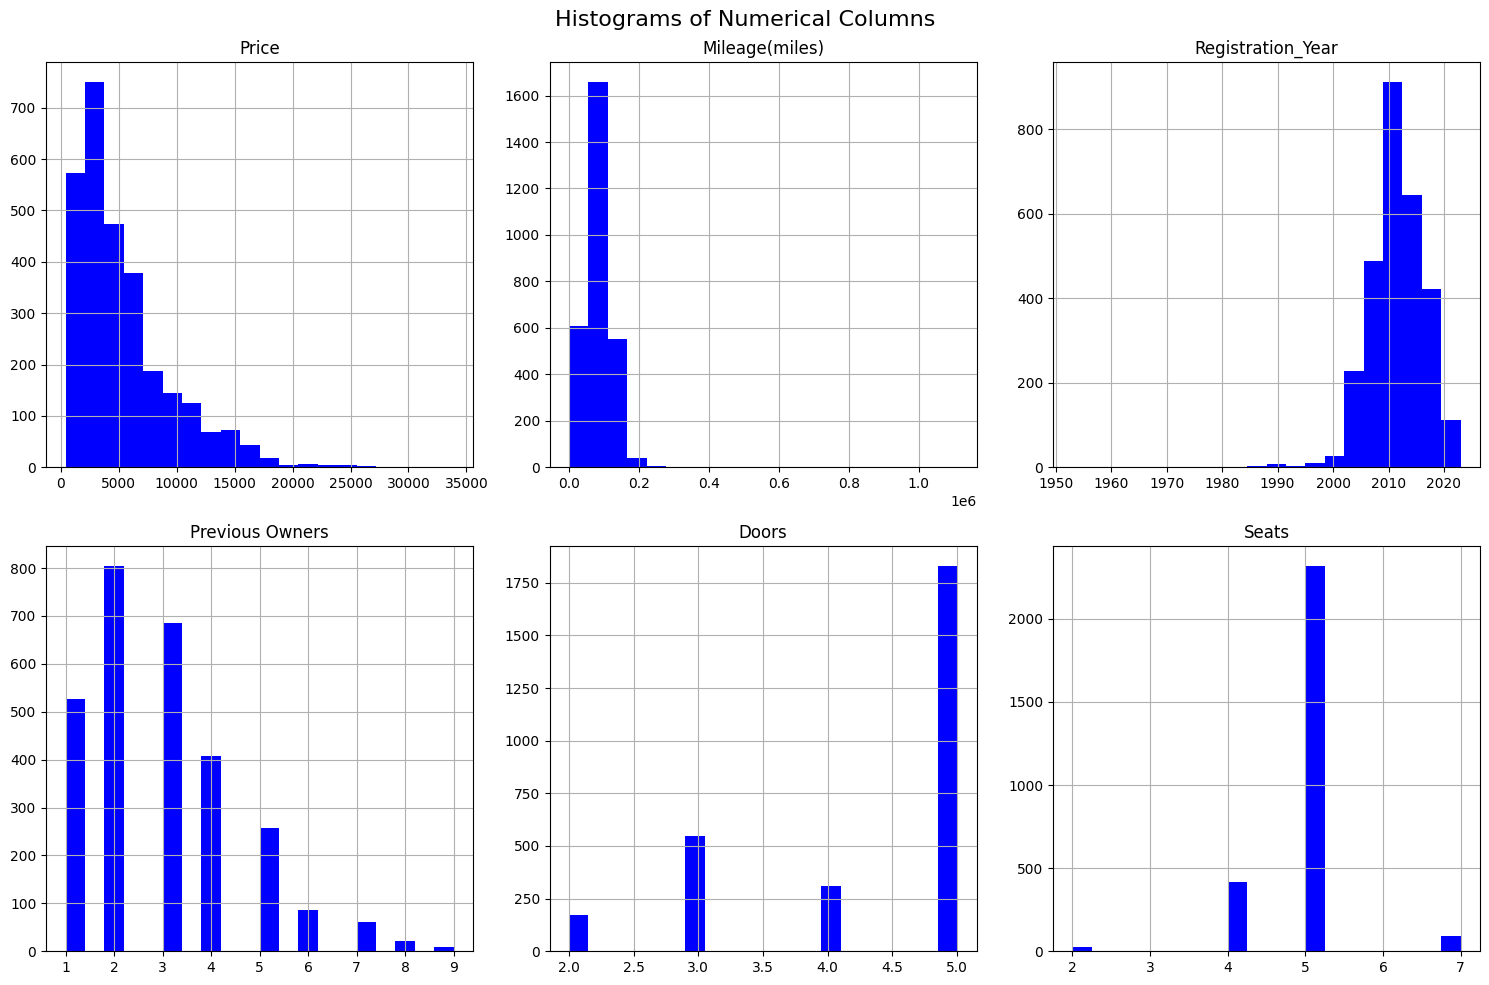

In [39]:
numeric_columns = df1_numericals.columns

num_rows = 2
num_cols = 3

fig, axes = plt.subplots(num_rows, num_cols, figsize=(15, 10))

fig.suptitle('Histograms of Numerical Columns', fontsize=16)

for i, variable in enumerate(numeric_columns):  
    row = i // num_cols
    col = i % num_cols
    ax = axes[row, col]
    ax.hist(df1_numericals[variable], color='blue', bins=20)
    ax.set_title(variable)
    ax.set_xlabel("")
    ax.grid(True)

plt.tight_layout()

plt.show()


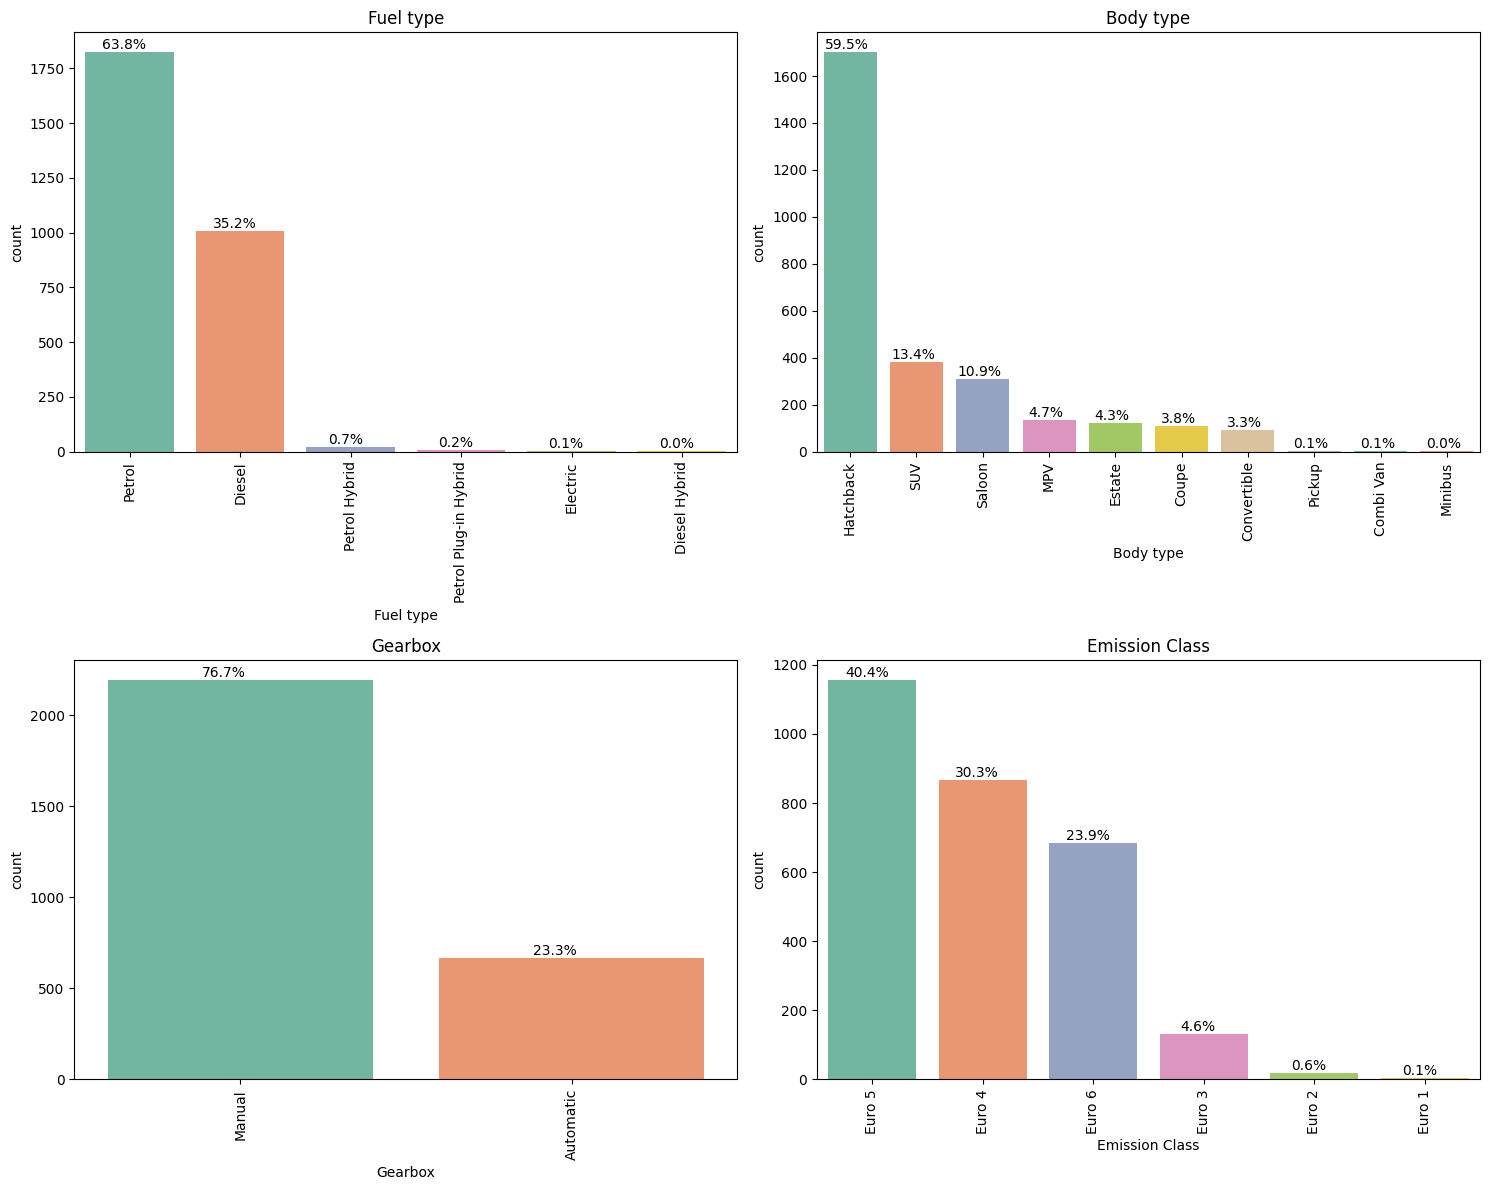

In [40]:
cat_columns = ['Fuel type', 'Body type', 'Gearbox', 'Emission Class']

plt.figure(figsize=(15, 12))

for i, variable in enumerate(cat_columns, 1):  
    plt.subplot(2, 2, i)  
    order = df1_categoricals[variable].value_counts().index  
    ax = sns.countplot(x=variable, data=df1_categoricals, order=order, palette='Set2')
    total = float(len(df1_categoricals[variable]))
    for p in ax.patches:
        percentage = '{:.1f}%'.format(100 * p.get_height() / total)
        x = p.get_x() + p.get_width() / 2 - 0.05
        y = p.get_height()
        ax.annotate(percentage, (x, y), ha='center', va='bottom') 
    plt.xticks(rotation=90)
    plt.title(variable)

plt.tight_layout()

plt.show()


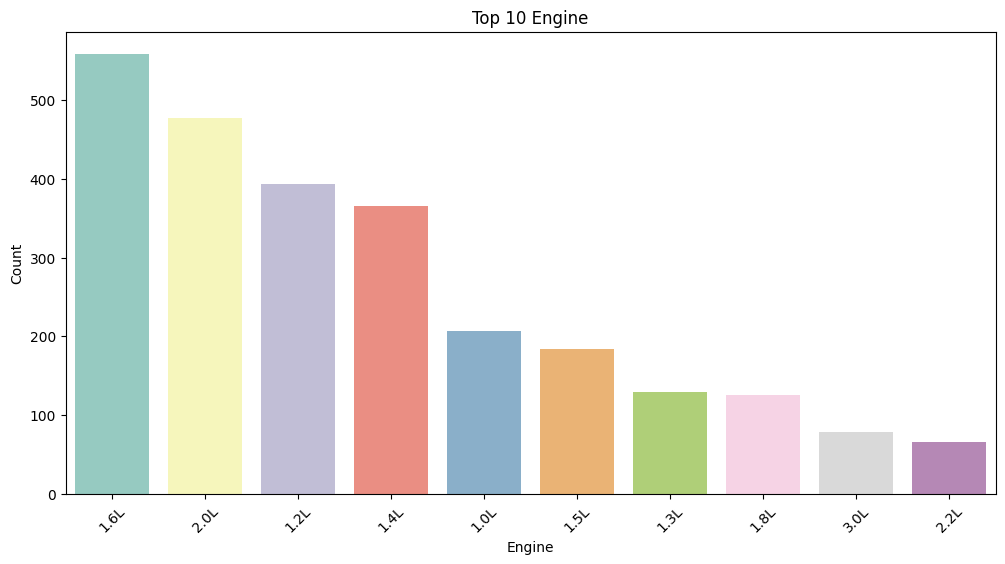

In [41]:
Engine_counts = df1['Engine'].value_counts()
top_10_Engine = Engine_counts.head(10)

plt.figure(figsize=(12, 6))
sns.set_palette("Set3")
ax = sns.barplot(x=top_10_Engine.index, y=top_10_Engine.values)
plt.title('Top 10 Engine')
plt.xlabel('Engine')
plt.ylabel('Count')
plt.xticks(rotation=45)


plt.show()

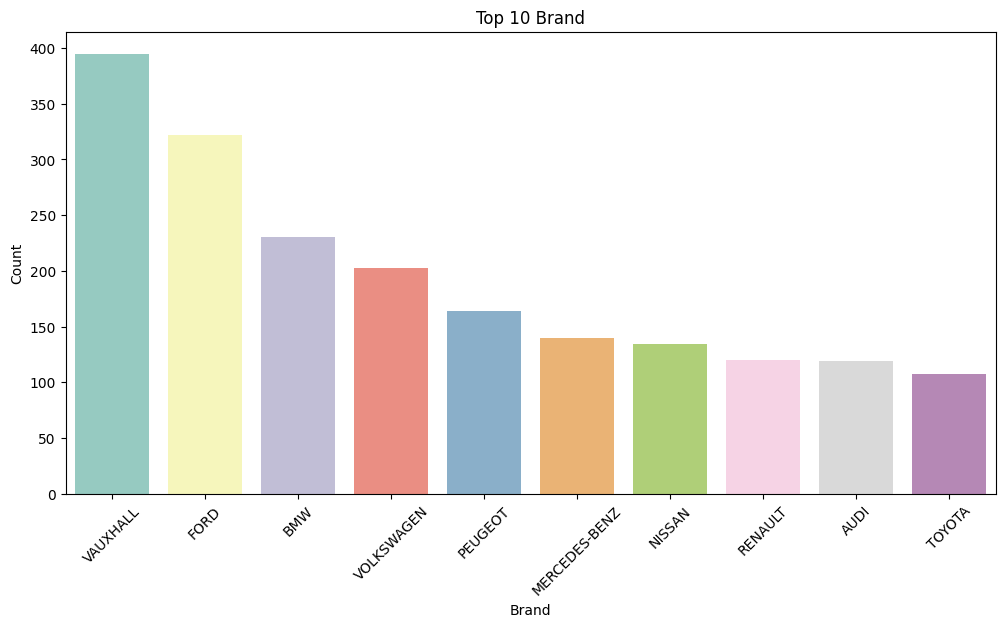

In [42]:
brand_counts = df1['Brand'].value_counts()
top_10_brand = brand_counts.head(10)

plt.figure(figsize=(12, 6))
sns.set_palette("Set3")
ax = sns.barplot(x=top_10_brand.index, y=top_10_brand.values)
plt.title('Top 10 Brand')
plt.xlabel('Brand')
plt.ylabel('Count')
plt.xticks(rotation=45)

plt.show()

>  Based on the data of used car sales in the UK, it can be summarized as follows:
> 
> 1. Fuel Type: The majority of used cars sold are fueled by petrol, accounting for 63.8% of total sales.
> 
> 2. Body Type: The majority of used cars sold have a Hatchback body type, accounting for 59.5% of total sales.
> 
> 3. Transmission Type (Gearbox): Manual transmission is the dominant choice, accounting for 76.7% of total used car sales.
> 
> 4. Emission Class: Used cars with Euro 5 emission class dominate sales, accounting for 40.4% of total sales.
> 
> 5. Engine: Engines with a capacity of 1.6 L are the most in demand by used car buyers in the UK.
> 
> 6. Brand: The Vauxhall brand is the most sought after by used car buyers, demonstrating its high popularity in the market.

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        4.2 Bivariate Analysis
   </p>
</div>


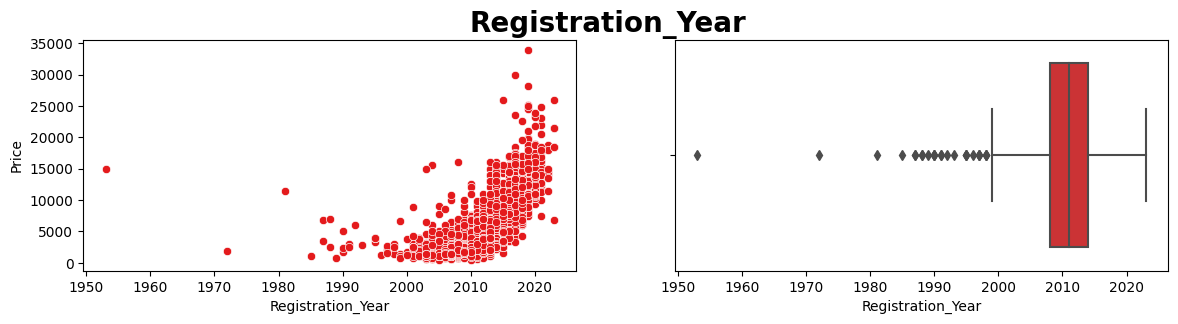

In [43]:
x = 'Registration_Year'

fig = plt.figure(figsize=(14, 3))
sns.set_palette("Set1")
plt.suptitle(x, size=20, weight='bold')

plt.subplot(1, 2, 1)
sns.scatterplot(x=x, y='Price', data=df1)

plt.subplot(1, 2, 2)
ax = sns.boxplot(x=x, data=df1)

plt.show()

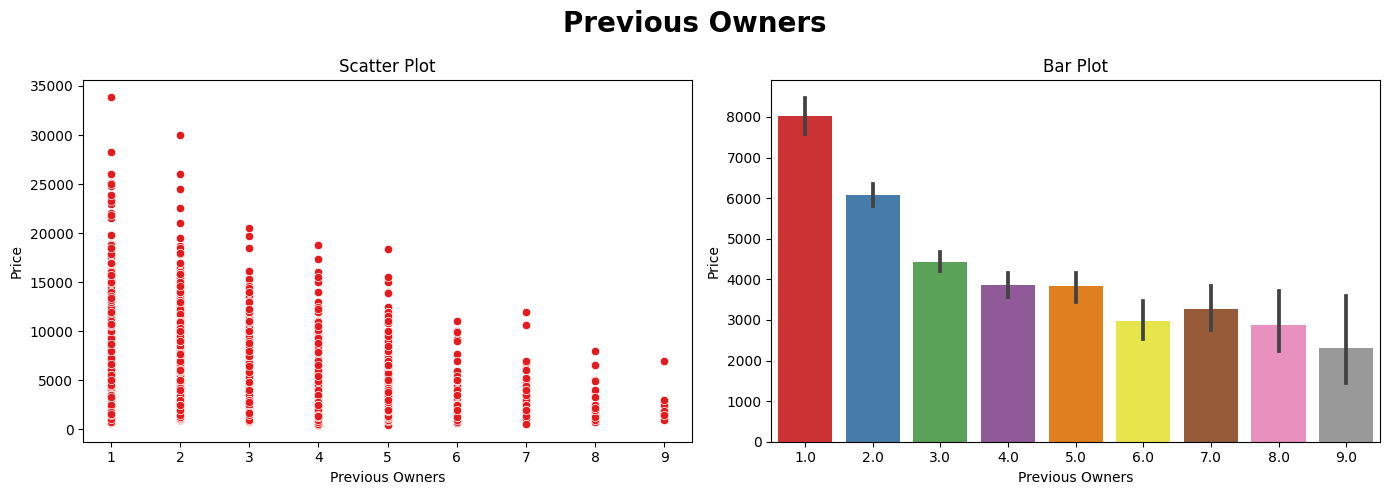

In [44]:
x = 'Previous Owners'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.set_palette("Set1")
sns.scatterplot(x=x, y='Price', data=df1, ax=axes[0])
axes[0].set_title('Scatter Plot')

sns.barplot(x=x, y='Price', data=df1, ax=axes[1])
axes[1].set_title('Bar Plot')

plt.suptitle(x, size=20, weight='bold')
plt.tight_layout()
plt.show()


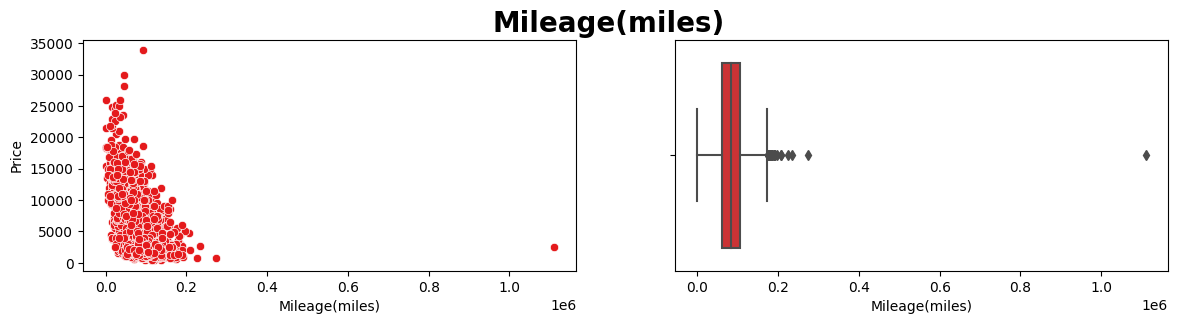

In [45]:
x = 'Mileage(miles)'

fig = plt.figure(figsize=(14, 3))
sns.set_palette("Set1")
plt.suptitle(x, size=20, weight='bold')

plt.subplot(1, 2, 1)
sns.scatterplot(x=x, y='Price', data=df1)

plt.subplot(1, 2, 2)
ax = sns.boxplot(x=x, data=df1)

plt.show()

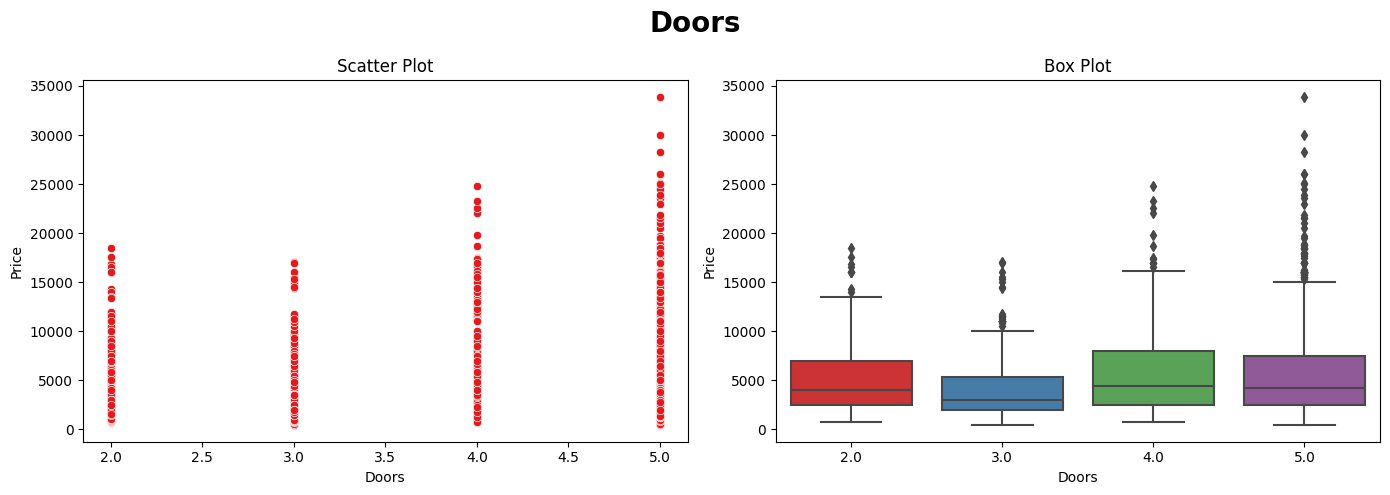

In [46]:
x = 'Doors'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.set_palette("Set1")
sns.scatterplot(x=x, y='Price', data=df1, ax=axes[0])
axes[0].set_title('Scatter Plot')

sns.boxplot(x=x, y='Price', data=df1, ax=axes[1])
axes[1].set_title('Box Plot')

plt.suptitle(x, size=20, weight='bold')
plt.tight_layout()
plt.show()


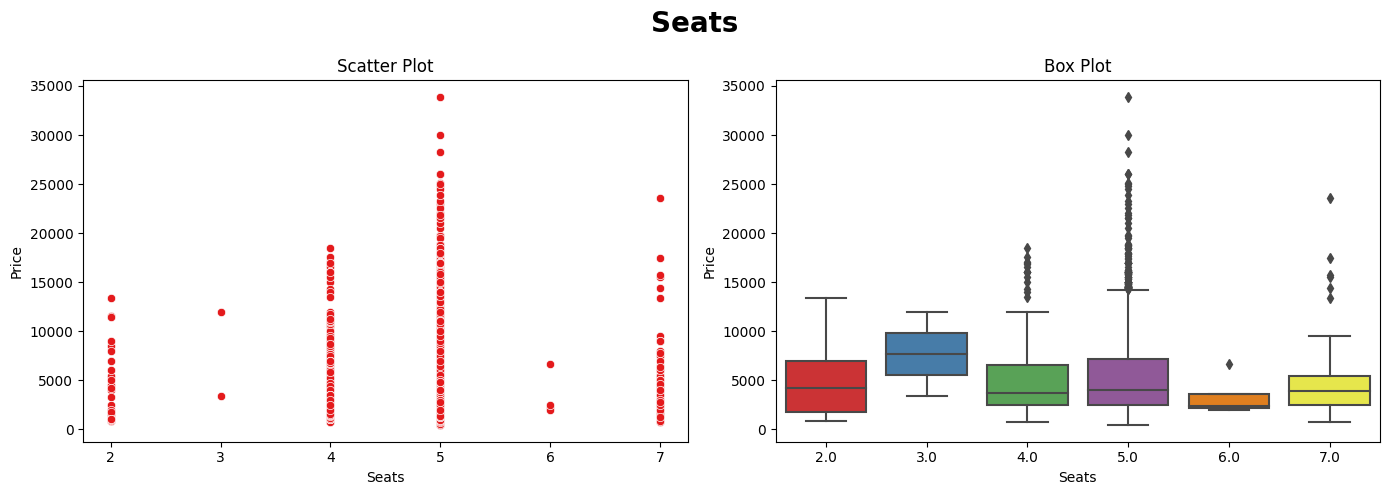

In [47]:
x = 'Seats'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.set_palette("Set1")
sns.scatterplot(x=x, y='Price', data=df1, ax=axes[0])
axes[0].set_title('Scatter Plot')

sns.boxplot(x=x, y='Price', data=df1, ax=axes[1])
axes[1].set_title('Box Plot')

plt.suptitle(x, size=20, weight='bold')
plt.tight_layout()
plt.show()


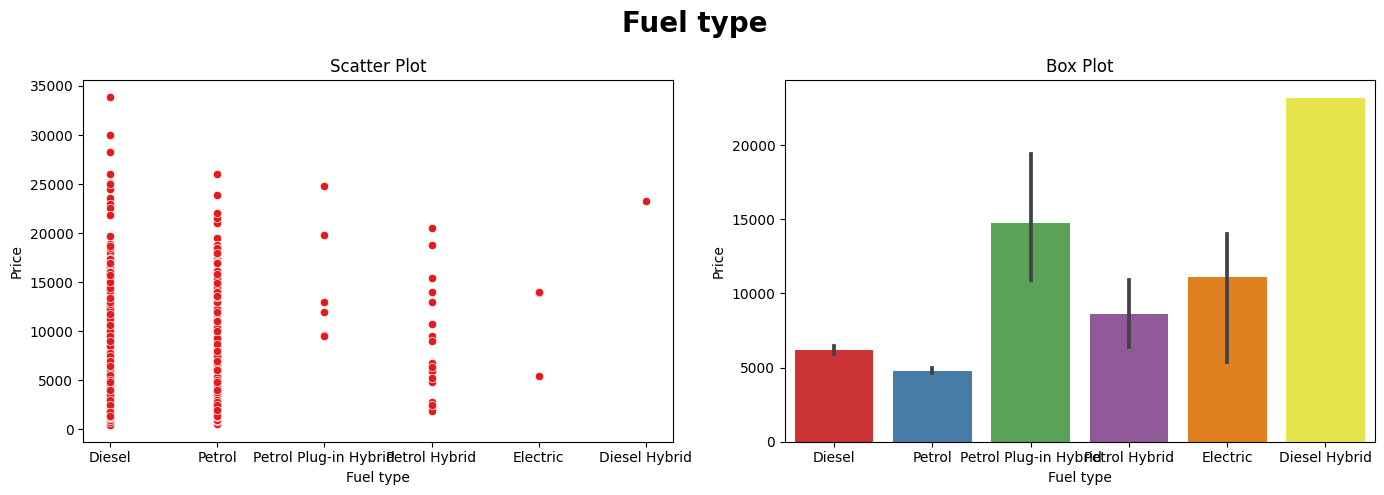

In [48]:
x = 'Fuel type'

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.set_palette("Set1")
sns.scatterplot(x=x, y='Price', data=df1, ax=axes[0])
axes[0].set_title('Scatter Plot')

sns.barplot(x=x, y='Price', data=df1, ax=axes[1])
axes[1].set_title('Box Plot')

plt.suptitle(x, size=20, weight='bold')
plt.tight_layout()
plt.show()


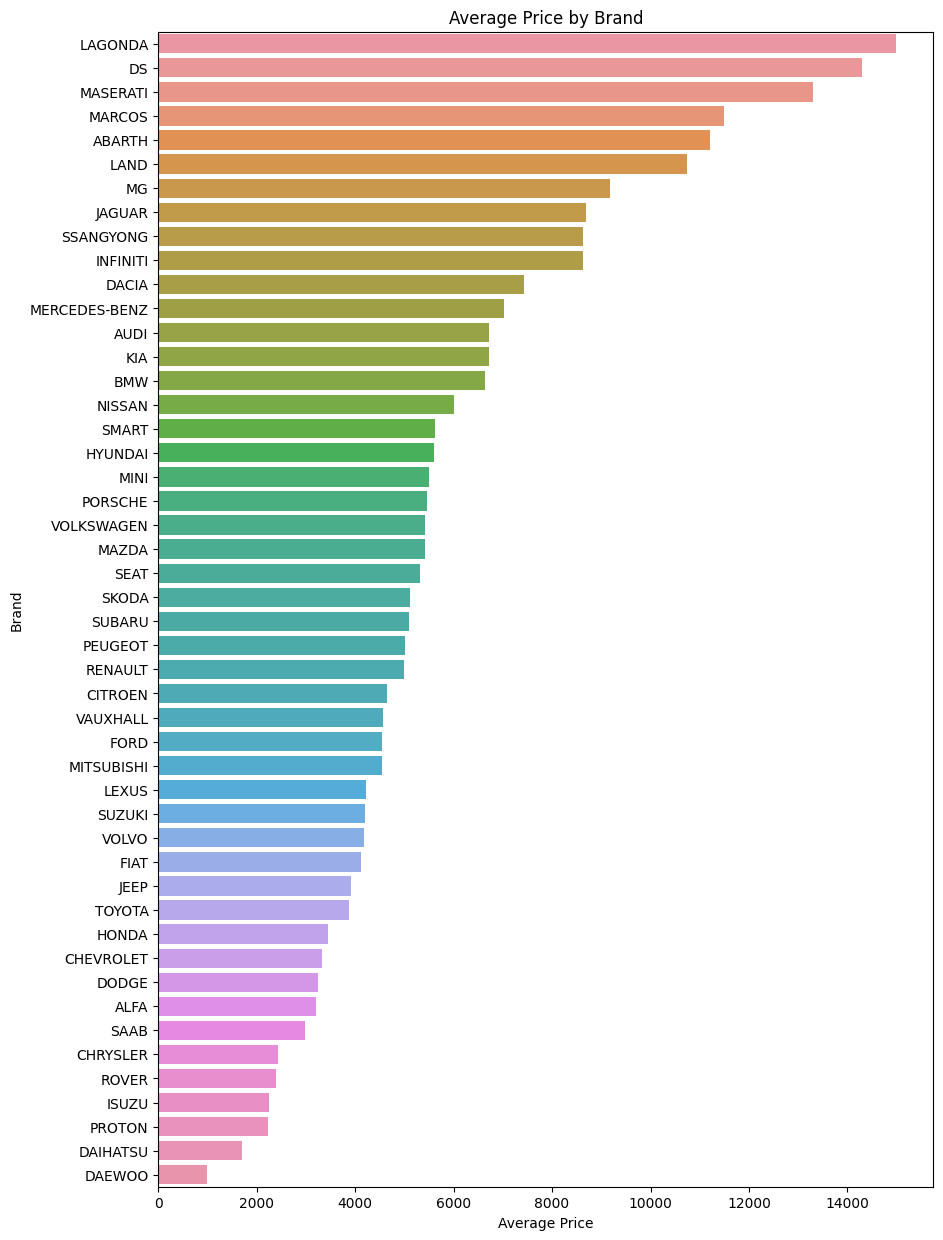

In [49]:
brand_prices = df1.groupby('Brand')['Price'].mean().sort_values(ascending=False)

# Membuat plot
plt.figure(figsize=(10, 15))
sns.set_palette("viridis")
ax = sns.barplot(x=brand_prices.values, y=brand_prices.index, orient='h')
plt.title('Average Price by Brand')
plt.xlabel('Average Price')
plt.ylabel('Brand')
plt.xticks(rotation=0)

plt.show()


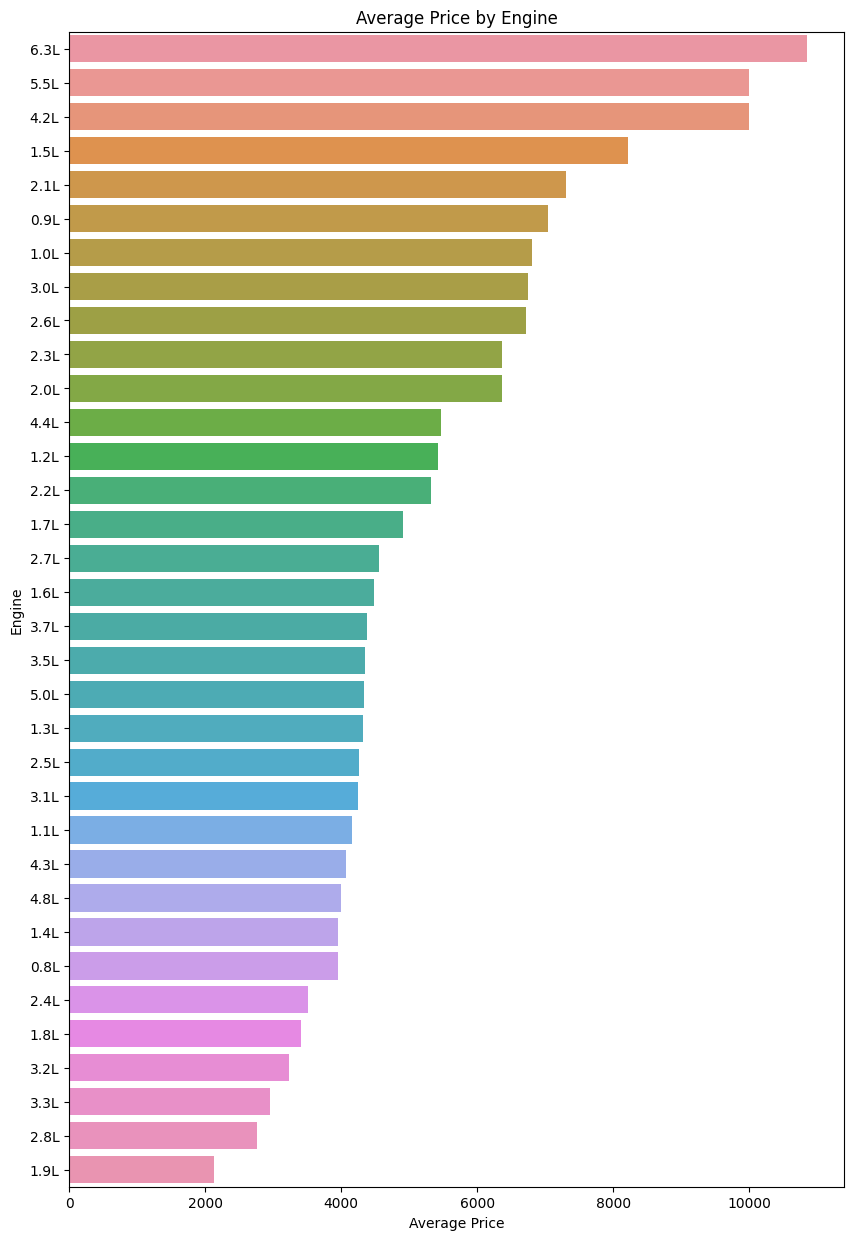

In [50]:
brand_prices = df1.groupby('Engine')['Price'].mean().sort_values(ascending=False)

# Membuat plot
plt.figure(figsize=(10, 15))
sns.set_palette("Set3")
ax = sns.barplot(x=brand_prices.values, y=brand_prices.index, orient='h')
plt.title('Average Price by Engine')
plt.xlabel('Average Price')
plt.ylabel('Engine')
plt.xticks(rotation=0)

plt.show()


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        4.3 Multivariate Analysis
   </p>
</div>


<Axes: title={'center': 'Price VS Registration_Year on Gearbox'}, xlabel='Price', ylabel='Registration_Year'>

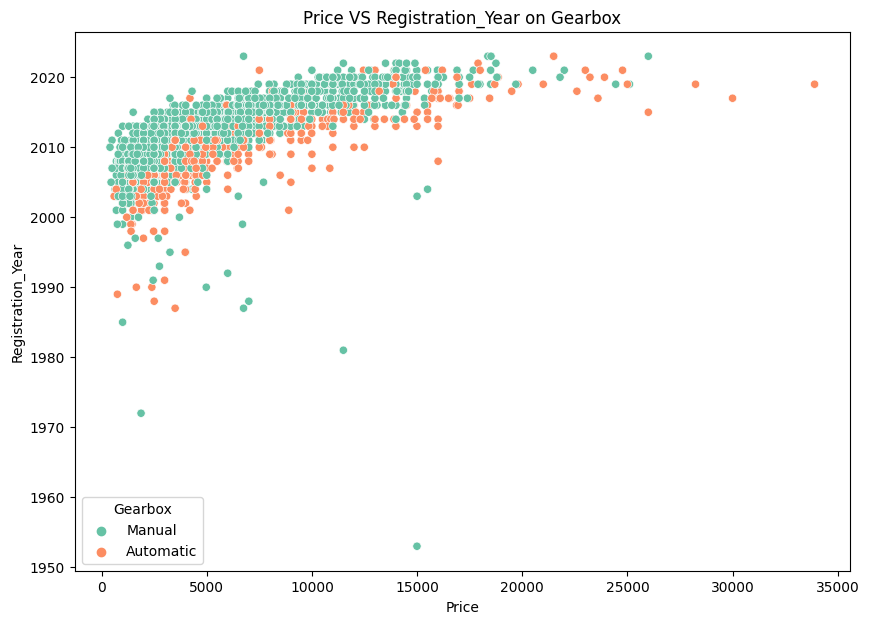

In [51]:
plt.figure(figsize=(10,7))
sns.set_palette("Set2")

plt.title("Price VS Registration_Year on Gearbox")
sns.scatterplot(y='Registration_Year', x='Price', hue='Gearbox', data=df1)

<Axes: title={'center': 'Price VS Mileage(miles) on Gearbox'}, xlabel='Price', ylabel='Mileage(miles)'>

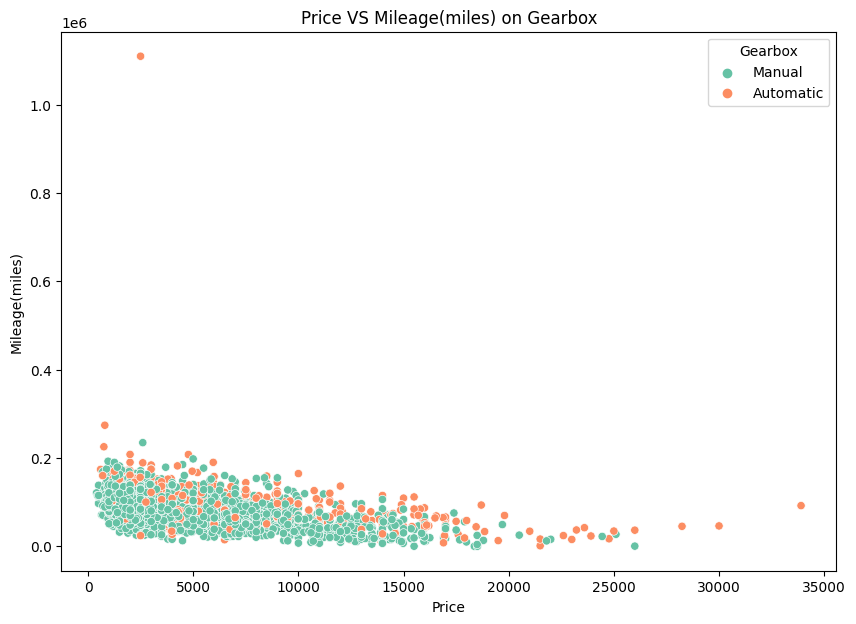

In [52]:
plt.figure(figsize=(10,7))
sns.set_palette("Set2")

plt.title("Price VS Mileage(miles) on Gearbox")
sns.scatterplot(y='Mileage(miles)', x='Price', hue='Gearbox', data=df1)

<Axes: title={'center': 'Price VS Emission Class on Gearbox'}, xlabel='Emission Class', ylabel='Price'>

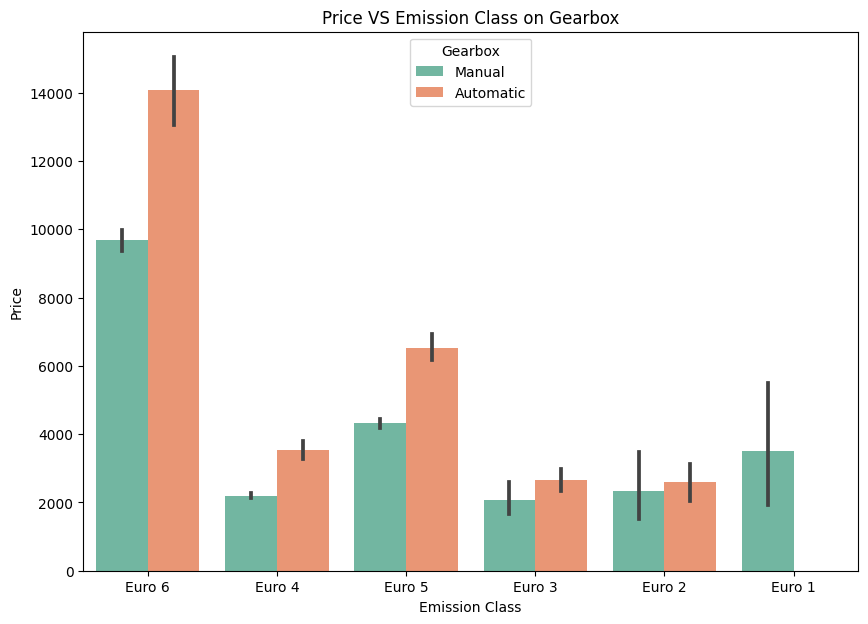

In [53]:
plt.figure(figsize=(10,7))
sns.set_palette("Set2")

plt.title("Price VS Emission Class on Gearbox")
sns.barplot(y='Price', x='Emission Class', hue='Gearbox', data=df1)

<Axes: title={'center': 'Price VS Emission Class on Gearbox'}, xlabel='Fuel type', ylabel='Price'>

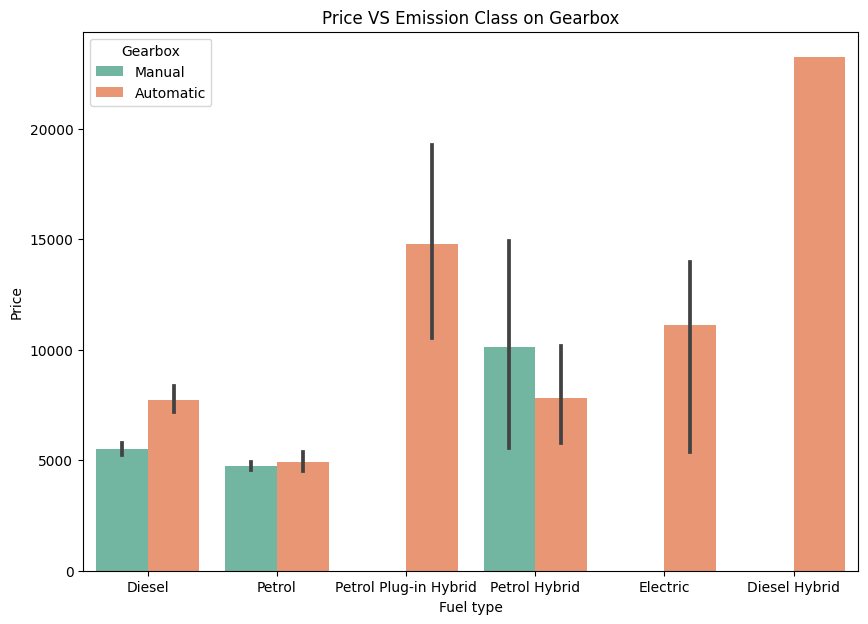

In [54]:
plt.figure(figsize=(10,7))
sns.set_palette("Set2")

plt.title("Price VS Emission Class on Gearbox")
sns.barplot(y='Price', x='Fuel type', hue='Gearbox', data=df1)

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        4.4 Correlation 
</div>


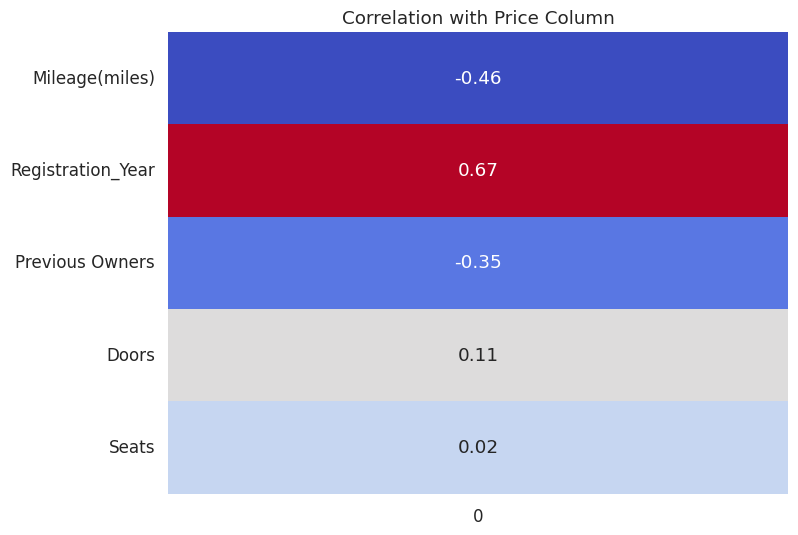

In [55]:
selected_columns = ['Mileage(miles)', 'Registration_Year', 'Previous Owners', 'Doors', 'Seats']
target_corr = df1[selected_columns].corrwith(df1['Price'])

# Plot korelasi dengan heatmap
plt.figure(figsize=(8, 6))
sns.set(font_scale=1.1)
sns.set_style("white")
sns.set_palette("PuBuGn_d")
sns.heatmap(target_corr.to_frame(), cmap="coolwarm", annot=True, fmt='.2f', cbar=False)
plt.title('Correlation with Price Column')
plt.show()


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        5. Data Preprocessing
   </p>
</div>


In [56]:
df2 = df1.copy()

In [57]:
df2.head(2)

,Brand,Price,Mileage(miles),Registration_Year,Previous Owners,Fuel type,Body type,Engine,Gearbox,Doors,Seats,Emission Class
0,SKODA,6900,70189,2016,3.0,Diesel,Hatchback,1.4L,Manual,5.0,5.0,Euro 6
1,VAUXHALL,1495,88585,2008,4.0,Petrol,Hatchback,1.2L,Manual,3.0,5.0,Euro 4


In [58]:
numerical_features = ['Price', 'Mileage(miles)', 'Registration_Year', 'Previous Owners', 'Doors', 'Seats']

robust_scaler = RobustScaler()

df2[numerical_features] = robust_scaler.fit_transform(df2[numerical_features])

def count_outliers(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    return ((series < lower_bound) | (series > upper_bound)).sum()

for feature in numerical_features :
    num_outliers = count_outliers(df2[feature])
    print(f'Number of outliers in {feature}: {num_outliers}')

Number of outliers in Price: 157
Number of outliers in Mileage(miles): 25
Number of outliers in Registration_Year: 26
Number of outliers in Previous Owners: 31
Number of outliers in Doors: 0
Number of outliers in Seats: 539


In [59]:
label_encoder = LabelEncoder()

In [60]:
categorical_features = ['Brand', 'Fuel type', 'Body type', 'Engine', 'Gearbox', 'Emission Class']
for feature in categorical_features:
    df2[feature] = label_encoder.fit_transform(df2[feature])
    
    

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        5.1 Correlation Spearman
   </p>
</div>


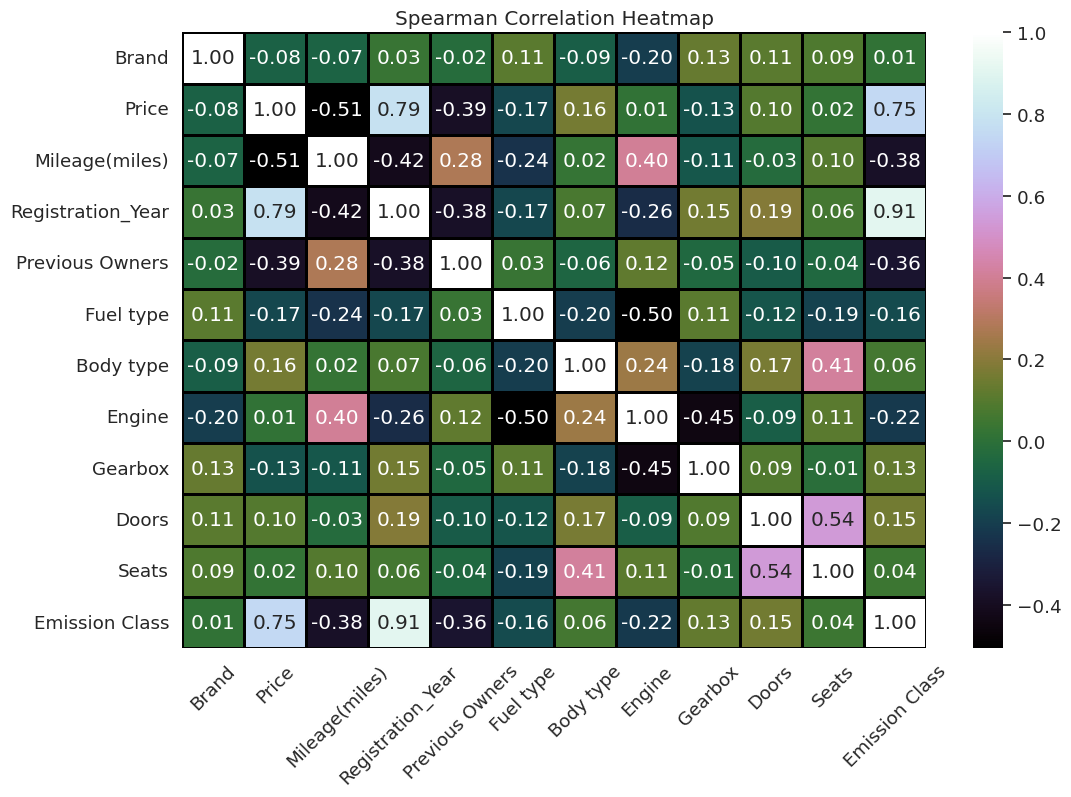

In [61]:
spearman_corr = df2.corr(method='spearman')

plt.figure(figsize=(12, 8))
sns.set(font_scale=1.2)
sns.heatmap(spearman_corr, annot=True, cmap='cubehelix', fmt=".2f", linewidths=1, linecolor='black')
plt.title('Spearman Correlation Heatmap')
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        5.2 Normalize Data
   </p>
</div>


In [62]:
X = df2.drop('Price', axis=1).values
y = df2['Price'].values

In [63]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [64]:
X_scaled_df = pd.DataFrame(X_scaled)

X_scaled_df.describe().T.style.background_gradient(axis=0, cmap='cubehelix')


,count,mean,std,min,25%,50%,75%,max
0,2859.000000,0.000000,1.000175,-1.681005,-0.838212,0.069411,1.171524,1.366015
1,2859.000000,-0.000000,1.000175,-2.121031,-0.609925,-0.024876,0.539249,25.914723
2,2859.000000,-0.000000,1.000175,-11.719593,-0.658416,-0.055079,0.548258,2.358269
3,2859.000000,-0.000000,1.000175,-1.222079,-0.580521,0.061037,0.702595,3.910384
4,2859.000000,-0.000000,1.000175,-1.351425,-1.351425,0.723615,0.723615,2.106975
5,2859.000000,-0.000000,1.000175,-2.292452,-0.425314,-0.425314,0.041470,1.908608
6,2859.000000,0.000000,1.000175,-1.776425,-0.716796,-0.081019,0.766683,5.217121
7,2859.000000,0.000000,1.000175,-1.814605,0.551084,0.551084,0.551084,0.551084
8,2859.000000,-0.000000,1.000175,-2.374502,-1.355178,0.683472,0.683472,0.683472
9,2859.000000,0.000000,1.000175,-4.927855,0.184787,0.184787,0.184787,3.593216


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        5.3 Re-Check Data
   </p>
</div>


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
       Hypothesis Testing
   </p>
</div>


T-statistic: 11.627707511571488
P-value: 6.62381030778328e-31


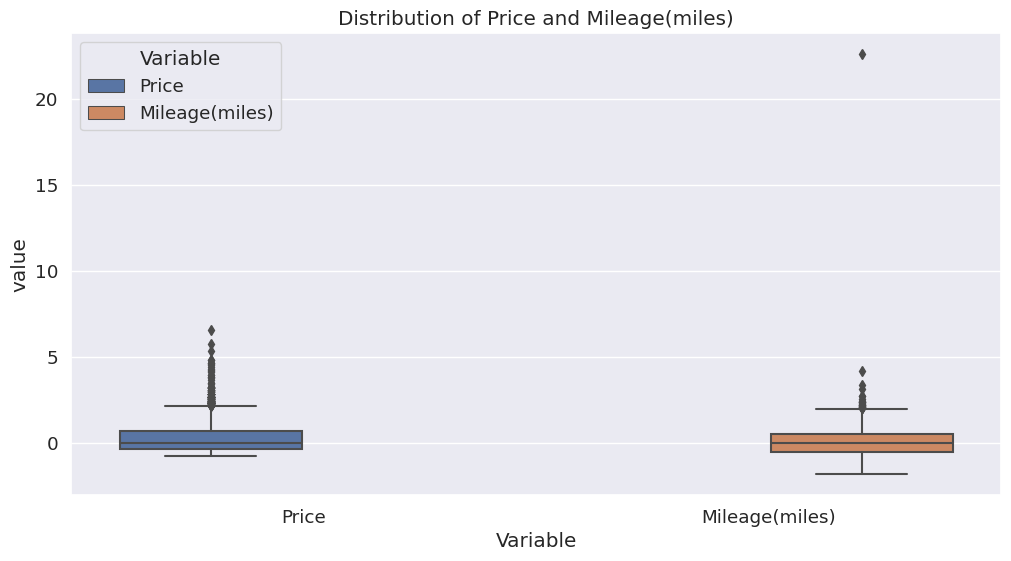

T-statistic: -1.0676503536812763
P-value: 0.2857233492425267


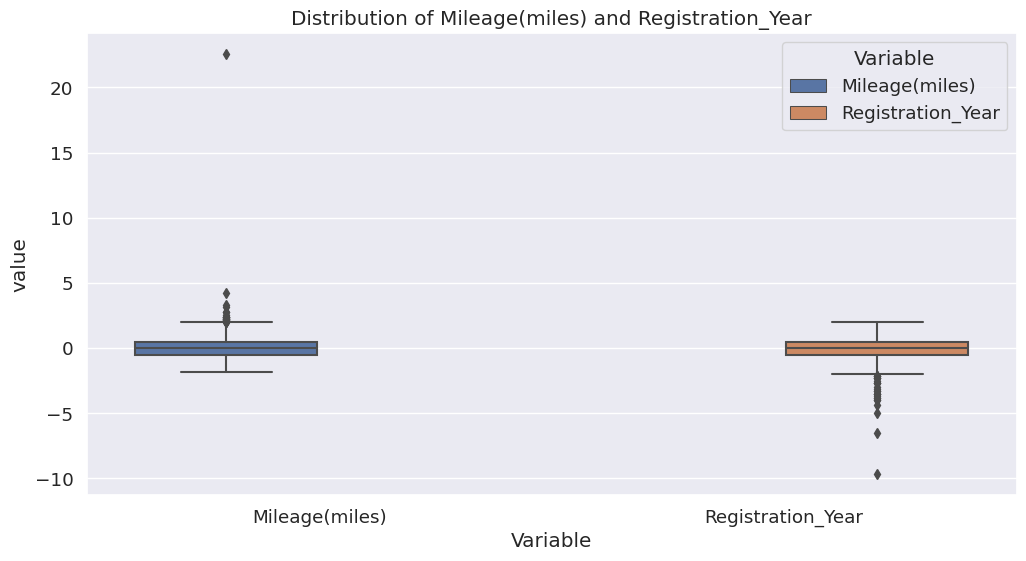

T-statistic: 4.380439431149007
P-value: 1.2055677555134061e-05


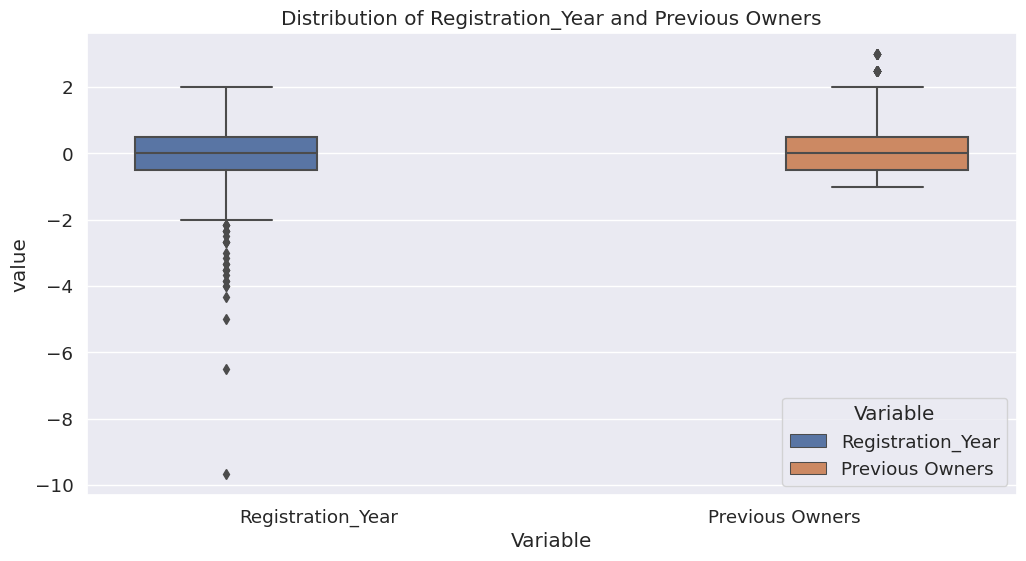

T-statistic: 16.70146305524736
P-value: 3.537483365190055e-61


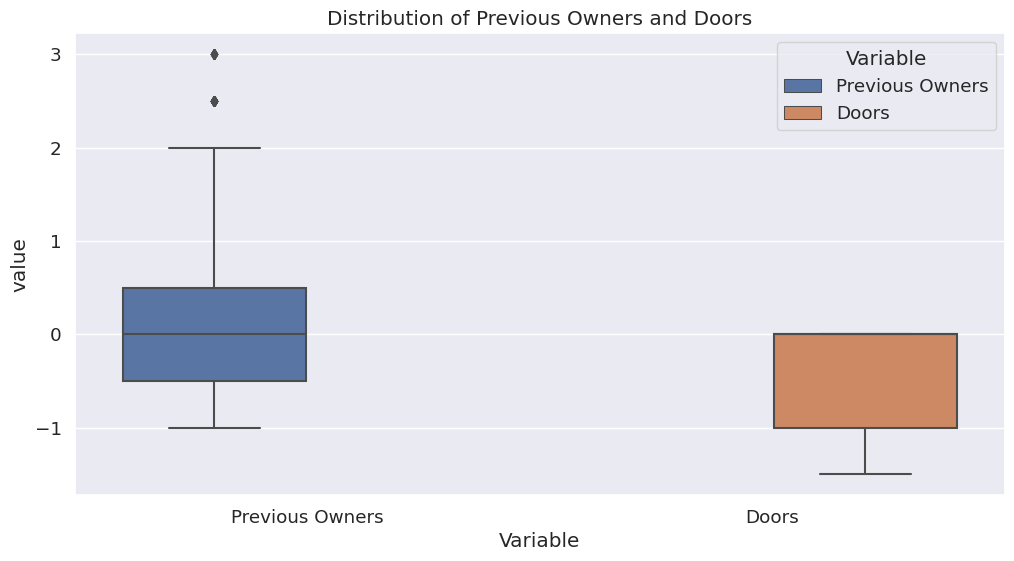

T-statistic: -15.855423169935573
P-value: 1.932598233845403e-55


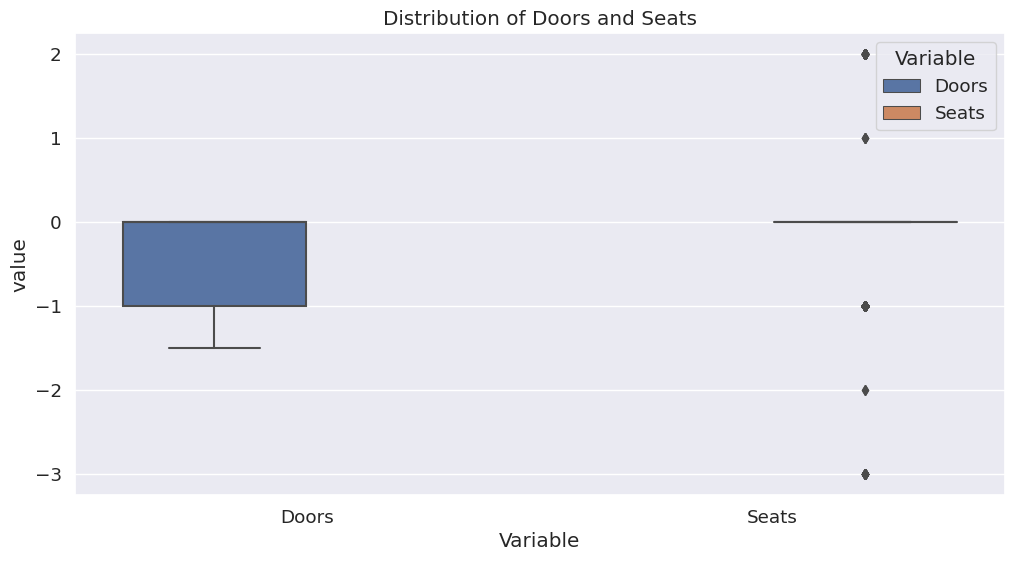

In [65]:
def hypothesis_testing(df, column1, column2):
    t_stat, p_val = stats.ttest_ind(df[column1], df[column2])

    print("T-statistic:", t_stat)
    print("P-value:", p_val)

    plt.figure(figsize=(12, 6))
    sns.boxplot(x="Variable", y="value", hue="Variable",
                data=pd.melt(df[[column1, column2]], var_name="Variable", value_name="value"))

    plt.title(f'Distribution of {column1} and {column2}')
    plt.show()

columns_for_testing = ['Price', 'Mileage(miles)', 'Registration_Year', 'Previous Owners', 'Doors', 'Seats']

for i in range(len(columns_for_testing) - 1):
    hypothesis_testing(df2, columns_for_testing[i], columns_for_testing[i + 1])

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        5.4 Split Data
   </p>
</div>


In [66]:
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        6. Modeling
   </p>
</div>


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        6.1 MLP
   </p>
</div>


In [67]:
model = Sequential()
model.add(Dense(128, activation='relu', input_shape=(X_train.shape[1],)))
model.add(Dropout(0.2))  
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))  
model.add(Dense(1, activation='linear'))  


In [68]:
model.compile(optimizer='adam', loss='mean_squared_error')

In [69]:
history = model.fit(X_train, y_train, epochs=50, batch_size=32, validation_split=0.1, verbose=1)


Epoch 1/50
65/65 [==============================] - 1s 4ms/step - loss: 0.3779 - val_loss: 0.1991
Epoch 2/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1973 - val_loss: 0.1734
Epoch 3/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1860 - val_loss: 0.1798
Epoch 4/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1611 - val_loss: 0.1568
Epoch 5/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1663 - val_loss: 0.1535
Epoch 6/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1571 - val_loss: 0.1693
Epoch 7/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1483 - val_loss: 0.1389
Epoch 8/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1462 - val_loss: 0.1591
Epoch 9/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1443 - val_loss: 0.1395
Epoch 10/50
65/65 [==============================] - 0s 2ms/step - loss: 0.1407 - val_loss: 0.1469
Epoch 11/50
65/65 [

In [70]:
loss = model.evaluate(X_test, y_test, verbose=0)
loss

0.15433138608932495

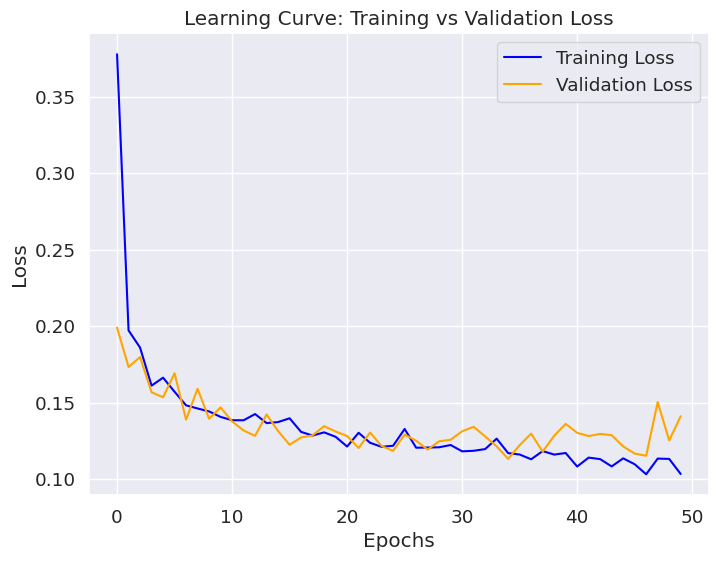

In [71]:
plt.figure(figsize=(8, 6))
plt.plot(history.history['loss'], label='Training Loss', color='blue')
plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Learning Curve: Training vs Validation Loss')
plt.legend()
plt.show()


In [72]:
predictions = model.predict(X_test)


18/18 [==============================] - 0s 997us/step


In [73]:
mae = mean_absolute_error(y_test, predictions)
print(f'MAE on test data: {mae}')

MAE on test data: 0.25752804653568934


In [74]:
mse = mean_squared_error(y_test, predictions)
print(f'MSE on test data: {mse}')

MSE on test data: 0.15433137692546114


In [75]:
rmse = np.sqrt(mse)
print(f'RMSE on test data: {rmse}')

RMSE on test data: 0.3928503238199775


In [76]:
r2 = r2_score(y_test, predictions)
print(f'R-squared value on test data: {r2}')


R-squared value on test data: 0.8181374975981643


<div style="background-color: navy; padding: 15px; border-radius: 10px;">
    <p style="color: white; font-size: 15px; font-weight: bold;">
        7. Finish
   </p>
</div>


<div style="background-color: #ffffff; color: #000000; padding: 10px; border-radius: 5px;">
    <p style="font-size: 16px; font-weight: bold;">
       If you discovered this notebook to be useful or enjoyable, I'd greatly appreciate any upvotes.
    </p>
</div>


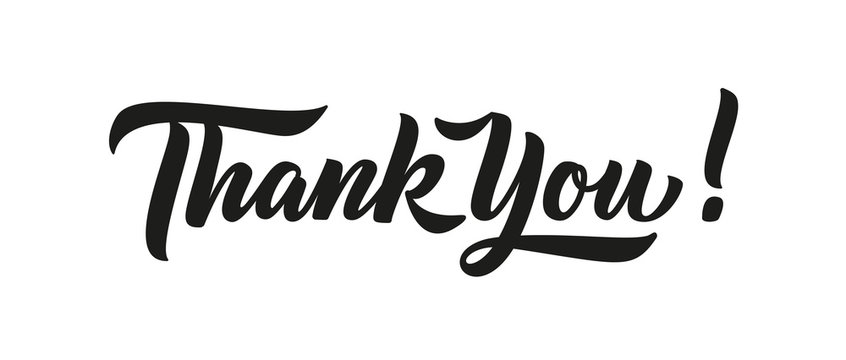